# Computer Vision - Project 2

Gradient-domain editing (Poisson blending) and panorama stitching (SIFT vs ORB). The code is in `src/p2_gradient_domain.py` and `src/p2_panorama.py`.

## Setup

Install dependencies from the repository root with `python -m pip install -r requirements.txt`.

For Google Colab, run `!git clone https://github.com/nghoang1162050/CO3057-BTL_17.git`, then `%cd CO3057-BTL_17`, then `!pip install -r requirements.txt` before running this notebook.

In [1]:
from pathlib import Path
import sys

repo_root = Path.cwd()
if not (repo_root / "src").is_dir():
    repo_root = repo_root.parent
if not (repo_root / "src").is_dir():
    raise FileNotFoundError("Open this notebook from the repository root or notebooks/ directory")
sys.path.insert(0, str(repo_root / "src"))

import matplotlib.pyplot as plt
import matplotlib.image as mpimg


def show(path, figsize=(14, 5)):
    plt.figure(figsize=figsize)
    plt.imshow(mpimg.imread(repo_root / path))
    plt.axis("off")
    plt.show()

## Part 1 - Poisson blending

The synthetic pair is a star on a flat backdrop pasted onto a sunset gradient. A hard paste shows the backdrop as a halo; Poisson blending replaces it with the surrounding color and keeps the star's edges. The seam score is the mean gradient magnitude in a thin ring around the mask boundary (lower means a less visible seam).

[P2 Part1] No complete custom image set -- using the synthetic demo pair


[P2 Part1] Poisson solve: 19577 unknown pixels/channel in 63.6 ms
[P2 Part1] seam score (background alone (reference)): 3.40
[P2 Part1] seam score (naive cut-paste): 62.67
[P2 Part1] seam score (feathered alpha blend): 11.99
[P2 Part1] seam score (Poisson (import gradients)): 3.42
[P2 Part1] seam score (Poisson (mixed gradients)): 3.74
[P2 Part1] Figures written to D:\git_pet\computer-vision\CO3057-BTL_17\outputs\p2_gradient_domain


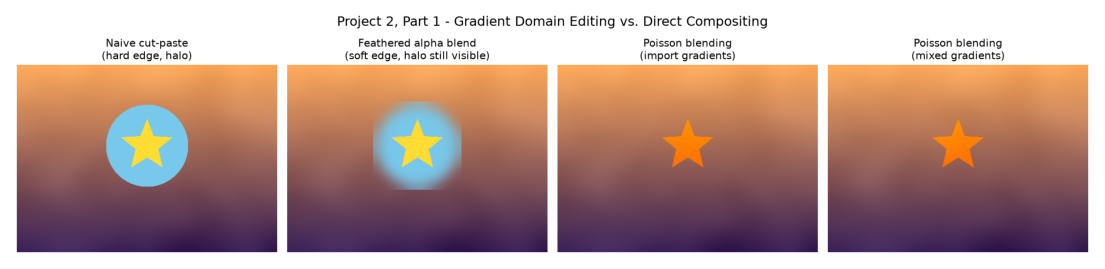

In [2]:
import p2_gradient_domain as gd

gd.run(out_dir=repo_root / "outputs" / "p2_gradient_domain")
show("outputs/p2_gradient_domain/02_comparison.png")

The same comparison on our own photos (cups and a teapot, placed on a wooden table and on a wall). Run any set with:

```bash
python src/p2_gradient_domain.py --data data/p2_gradient_domain_teapot_wall --out outputs/p2_gradient_domain_teapot_wall
```

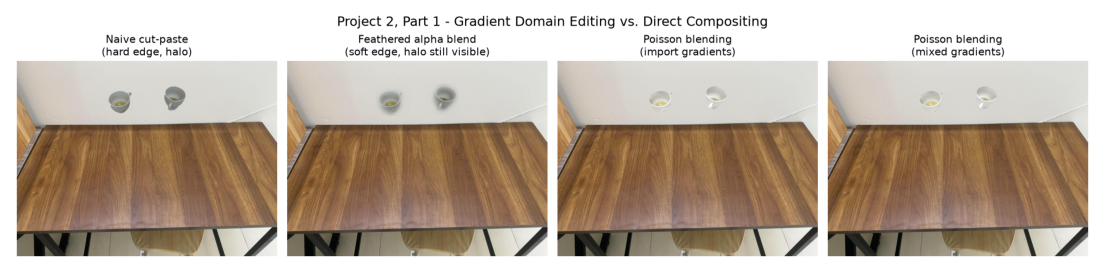

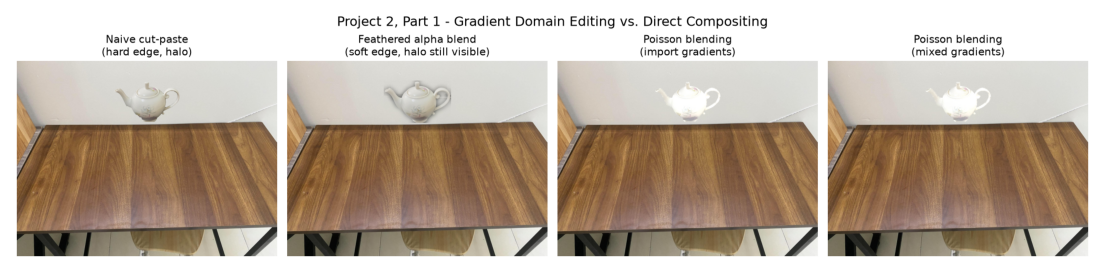

In [3]:
show("outputs/p2_gradient_domain_cups_wall/02_comparison.png")
show("outputs/p2_gradient_domain_teapot_wall/02_comparison.png")

## Part 2 - Panorama stitching

The pipeline is SIFT or ORB features, ratio-test matching, a RANSAC homography per pair, warping into the first view's frame, and feather blending. Running it takes about 15 s per set and writes about 90 MB of keypoint, match and panorama figures (git-ignored):

```bash
python src/p2_panorama.py
python src/p2_panorama.py --data data/p2_panorama_parallax --out outputs/p2_panorama_parallax
python src/p2_panorama.py --data data/p2_panorama_partial --out outputs/p2_panorama_partial
```

The cells below show the saved SIFT-vs-ORB comparison for each set.

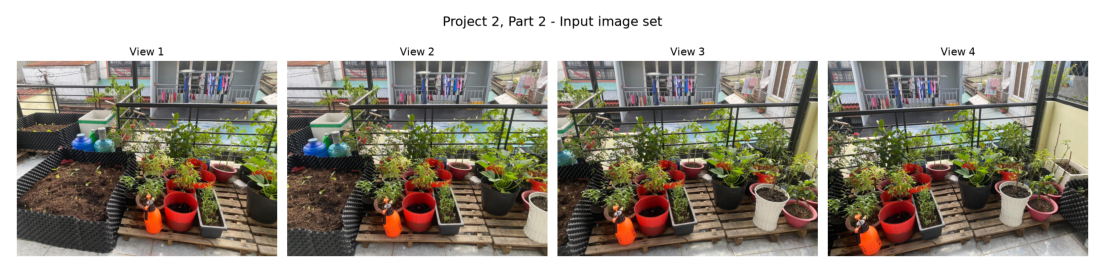

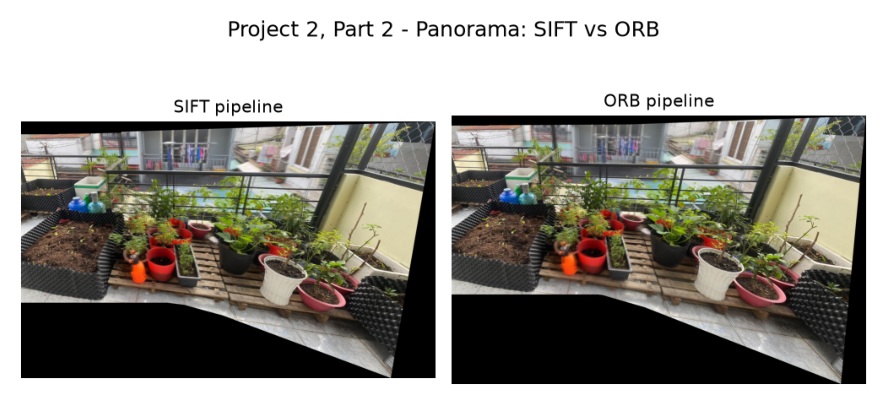

In [4]:
show("outputs/p2_panorama/00_inputs.png")
show("outputs/p2_panorama/04_sift_vs_orb.png")

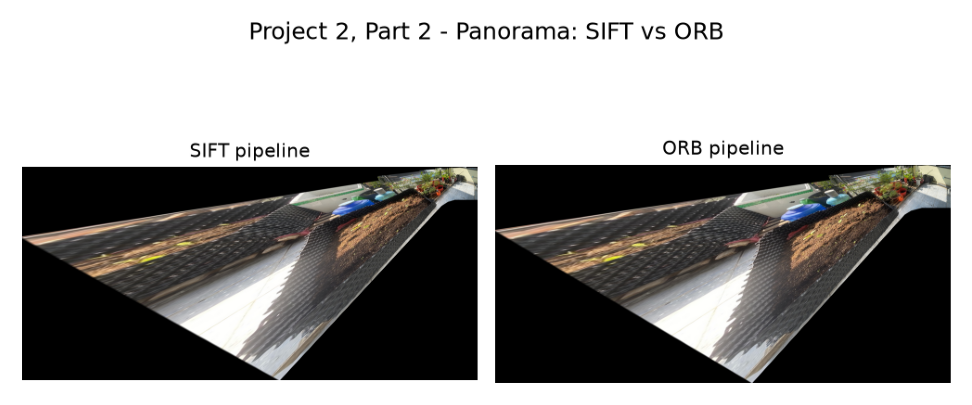

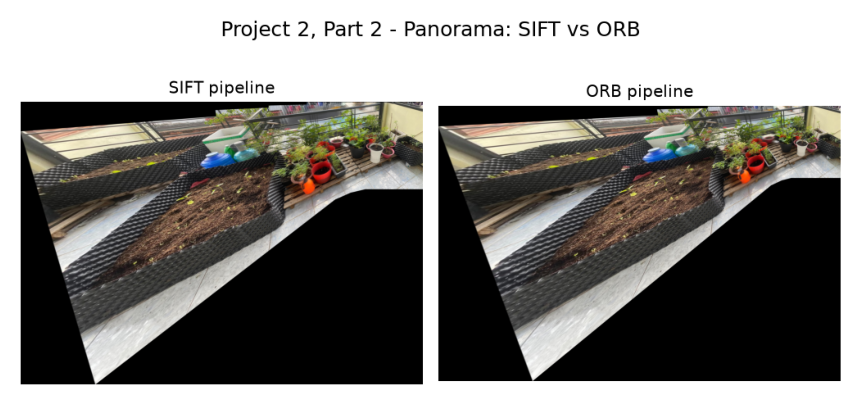

In [5]:
show("outputs/p2_panorama_parallax/04_sift_vs_orb.png")
show("outputs/p2_panorama_partial/04_sift_vs_orb.png")